# 03 · Volume and channel analysis
Questions 1–8: how much moves, through which channels, and when. **Value (KES moved) is never treated as revenue.**

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
o('q01_headline_kpis')

,period,attempts,successful_transactions,success_rate_pct,value_kes_bn,fee_income_kes_m,fee_per_successful_txn,active_customers,active_rate_pct
0,May 2025 - Oct 2026,"2,022,688.00","1,951,275.00",96.47,29.33,51.72,26.50,NaN,NaN
1,Oct 2025,"98,863.00","95,352.00",96.45,1.43,2.56,26.81,"15,729.00",73.20
2,Oct 2026,"147,378.00","142,328.00",96.57,2.17,3.75,26.36,"21,445.00",71.50


,month,successful,value_kes_m,fee_income_kes_k,success_rate_pct,active_customers
12,2026-05-01,120272,"1,817.20","3,171.00",96.54,18747
13,2026-06-01,124240,"1,885.70","3,276.00",96.39,19324
14,2026-07-01,129472,"1,984.20","3,438.00",96.65,19787
15,2026-08-01,132793,"2,034.90","3,516.00",96.42,20351
16,2026-09-01,138240,"2,106.90","3,679.00",96.50,20919
17,2026-10-01,142328,"2,172.20","3,752.00",96.57,21445


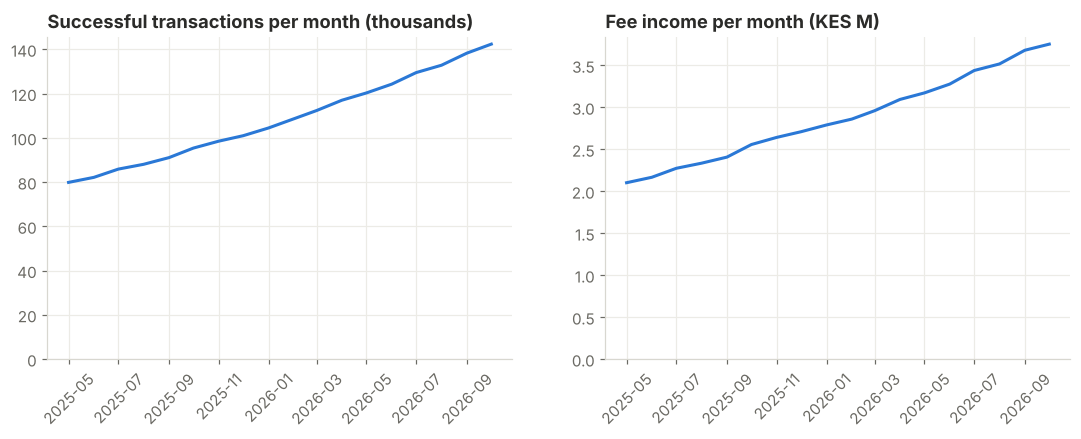

In [3]:
m = o('q02_monthly_trend'); m['month'] = pd.to_datetime(m.month)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(m.month, m.successful / 1e3, color=an.PRIMARY); axes[0].set_title("Successful transactions per month (thousands)")
axes[1].plot(m.month, m.fee_income_kes_k / 1e3, color=an.PRIMARY); axes[1].set_title("Fee income per month (KES M)")
for a in axes: a.set_ylim(0); a.tick_params(axis='x', rotation=45)
an.save(fig, "monthly_volume_and_fees"); m[['month','successful','value_kes_m','fee_income_kes_k','success_rate_pct','active_customers']].tail(6)

Successful transactions grew by about three quarters over 18 months, driven mainly by new customers (the customer base grew from about 18,500 to 30,000). Fee income grew at the same pace, and the fee per successful transaction stayed at about KES 26–27.

,month,mobile_app_pct,ussd_pct,agent_pct,atm_pct,internet_banking_pct,wallet_link_pct
0,2025-05-01,39.00,19.80,12.00,11.20,11.60,6.50
17,2026-10-01,46.10,12.90,11.50,11.40,11.70,6.50


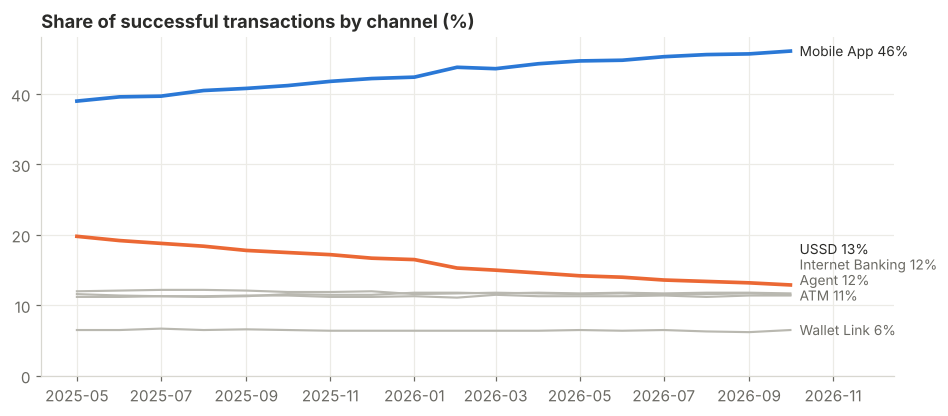

In [4]:
c = o('q03_channel_mix_over_time'); c['month'] = pd.to_datetime(c.month)
cols = {'mobile_app_pct': 'Mobile App', 'ussd_pct': 'USSD', 'agent_pct': 'Agent', 'atm_pct': 'ATM', 'internet_banking_pct': 'Internet Banking', 'wallet_link_pct': 'Wallet Link'}
fig, ax = plt.subplots(figsize=(10, 4))
ends = sorted(((c[col].iloc[-1], name) for col, name in cols.items()))
pos, last = {}, -99
for v, name in ends:                      # spread end labels so they never overlap
    last = max(v, last + 2.2); pos[name] = last
for col, name in cols.items():
    hi = name in ('Mobile App', 'USSD')
    ax.plot(c.month, c[col], color=an.PRIMARY if name == 'Mobile App' else an.HIGHLIGHT if name == 'USSD' else an.CONTEXT, lw=2.4 if hi else 1.4)
    ax.annotate(f"{name} {c[col].iloc[-1]:.0f}%", (c.month.iloc[-1], pos[name]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9,
                color=an.INK if hi else an.INK_MUTED)
ax.set_title("Share of successful transactions by channel (%)"); ax.set_ylim(0); ax.set_xlim(right=c.month.iloc[-1] + pd.Timedelta(days=75))
an.save(fig, "channel_mix_trend"); c.iloc[[0, -1]]

The **app gained about 7 points of share and USSD lost about 7**: customers are migrating from USSD to the app. The other channels held steady.

In [5]:
o('q04_channel_summary')

,channel,channel_group,successful,share_of_volume_pct,value_kes_m,share_of_value_pct,fee_income_kes_m,share_of_fees_pct,median_amount_kes,success_rate_pct,operational_failure_pct
0,Mobile App,Digital,843503,43.20,"8,917.00",30.40,16.06,31.00,"1,783.00",96.73,1.15
1,USSD,Digital,304776,15.60,"1,071.30",3.70,3.73,7.20,974.00,94.15,3.28
2,Agent,Assisted,229804,11.80,"2,200.40",7.50,10.59,20.50,"3,845.00",95.97,2.56
3,Internet Banking,Digital,227029,11.60,"14,813.10",50.50,14.06,27.20,"23,663.00",97.12,1.37
4,ATM,Self-service,220698,11.30,"1,524.00",5.20,7.28,14.10,"3,500.00",97.46,0.56
5,Wallet Link,Partner,125465,6.40,800.70,2.70,0.00,0.00,"2,627.00",98.60,1.38


**Each channel does a different job.** The app carries the most transactions (43%), but Internet Banking moves the most money (about half of all value, mostly SME interbank transfers). Agents carry 12% of volume and earn 21% of fee income (cash withdrawals). USSD has the lowest success rate.

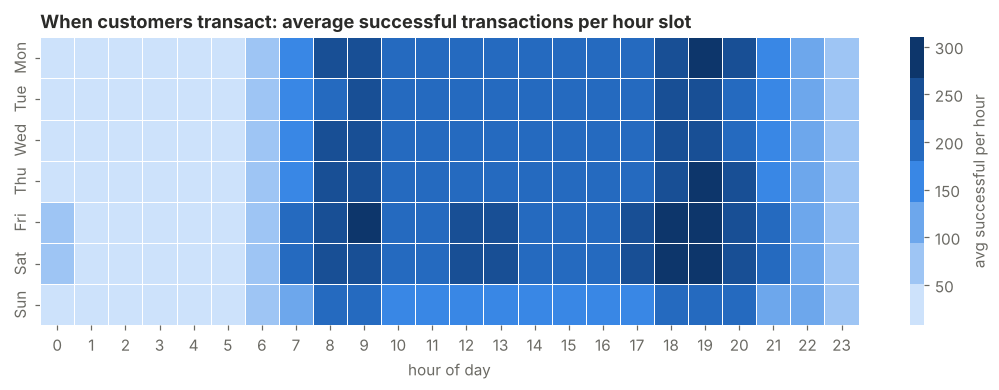

In [6]:
h = o('q06_hour_by_weekday').pivot(index='weekday', columns='hour', values='avg_successful_per_day_slot')
h = h.loc[['Mon','Tue','Wed','Thu','Fri','Sat','Sun']]
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(h, cmap=sns.color_palette(an.SEQ_BLUES, as_cmap=True), cbar_kws={'label': 'avg successful per hour'}, ax=ax, linewidths=0.5, linecolor='white')
ax.set_title("When customers transact: average successful transactions per hour slot"); ax.set_xlabel('hour of day'); ax.set_ylabel('')
an.save(fig, "hour_weekday_heatmap");

In [7]:
o('q07_payday_effect')

,period,days,avg_successful_per_day,avg_value_kes_m_per_day,avg_agent_withdrawal_attempts_per_day
0,Payday window (25th-2nd),153,"4,366.00",65.70,301.00
1,Rest of month,396,"3,241.00",48.70,219.00


Payday days (the 25th to the 2nd) are about **35% busier** than the rest of the month, for both transactions and value. Agent cash withdrawals follow the same pattern, and that matters for agent float (notebook 04).

,type_category,successful,value_kes_m,share_of_value_pct,fee_income_kes_m,share_of_fees_pct,fee_yield_bps
transaction_type,,,,,,,
Interbank Transfer,Transfer,184656,"16,478.70",56.20,21.61,41.80,13.10
Cash Withdrawal,Cash,345079,"2,564.60",8.70,17.87,34.60,69.70
Send to Mobile Wallet,Wallet,368870,"1,413.90",4.80,8.76,16.90,61.90
Bill Payment,Payment,217364,"1,416.20",4.80,3.48,6.70,24.60
Airtime Purchase,Payment,209120,48.10,0.20,0.00,0.00,0.00
Cash Deposit,Cash,105423,"1,159.80",4.00,0.00,0.00,0.00
Wallet Top-up,Wallet,125465,800.70,2.70,0.00,0.00,0.00
Merchant Payment,Payment,171833,455.90,1.60,0.00,0.00,0.00
Internal Transfer,Transfer,223465,"4,988.60",17.00,0.00,0.00,0.00


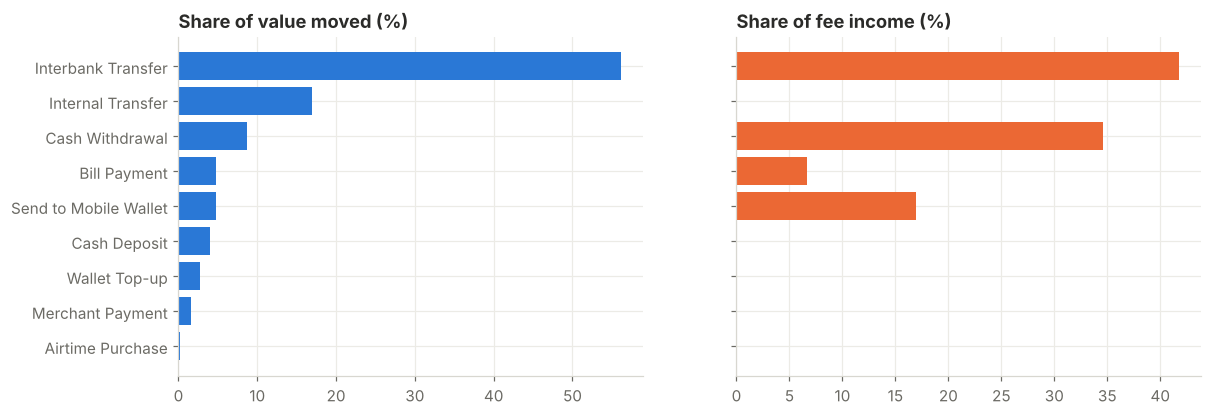

In [8]:
v = o('q08_value_vs_fees_by_type').set_index('transaction_type')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
v = v.sort_values('share_of_value_pct')
axes[0].barh(v.index, v.share_of_value_pct, color=an.PRIMARY); axes[0].set_title("Share of value moved (%)")
axes[1].barh(v.index, v.share_of_fees_pct, color=an.HIGHLIGHT); axes[1].set_title("Share of fee income (%)")
an.save(fig, "value_vs_fees_by_type"); v.sort_values('fee_income_kes_m', ascending=False)

**Value is not revenue.** Interbank transfers are 56% of value and 42% of fees. Cash withdrawals are only 9% of value but 35% of fee income. Internal transfers move 17% of value and earn nothing. A dashboard that ranks channels by value would point management at the wrong places.

In [9]:
o('q05_channel_by_type').head(12)

,channel,transaction_type,successful,value_kes_m,fee_income_kes_k,rank_in_channel
0,ATM,Cash Withdrawal,220698,"1,524.00","7,283.00",1
1,Agent,Cash Withdrawal,124381,"1,040.70","10,591.00",1
2,Agent,Cash Deposit,105423,"1,159.80",0.00,2
3,Internet Banking,Interbank Transfer,101165,"11,730.50","13,203.00",1
4,Internet Banking,Internal Transfer,68890,"2,455.00",0.00,2
5,Internet Banking,Bill Payment,56974,627.70,855.00,3
6,Mobile App,Send to Mobile Wallet,258106,"1,062.50","5,901.00",1
7,Mobile App,Merchant Payment,134153,379.60,0.00,2
8,Mobile App,Airtime Purchase,134001,34.50,0.00,3
9,Mobile App,Internal Transfer,117023,"2,069.20",0.00,4
